In [5]:
# Uber Fare Prediction

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [11]:
df = pd.read_csv("uber.csv")

# Remove unwanted columns
df.drop(["Unnamed: 0", "key"], axis=1, inplace=True)

# Convert datetime
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"],
    errors="coerce"
)

# Extract features
df["year"] = df["pickup_datetime"].dt.year
df["month"] = df["pickup_datetime"].dt.month
df["day"] = df["pickup_datetime"].dt.day
df["hour"] = df["pickup_datetime"].dt.hour

# Remove original datetime column
df.drop("pickup_datetime", axis=1, inplace=True)

# Remove null values
df.dropna(inplace=True)

In [12]:
# -------------------- Outlier Detection --------------------

Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[(df["fare_amount"] >= lower) &
        (df["fare_amount"] <= upper)]

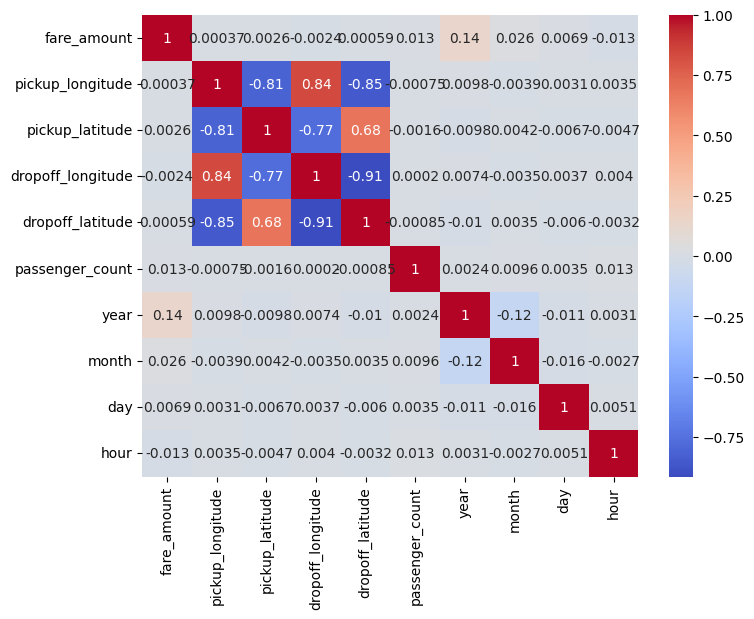

In [13]:
# -------------------- Correlation --------------------

plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.show()

In [14]:
# -------------------- Model Building --------------------

X = df.drop("fare_amount", axis=1)
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

# Random Forest Regression
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)


In [15]:
# -------------------- Evaluation --------------------

def evaluate(y_test, y_pred, name):
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    print(f"\n{name}")
    print("R2 Score :", round(r2, 4))
    print("RMSE     :", round(rmse, 4))

evaluate(y_test, y_pred_lr, "Linear Regression")
evaluate(y_test, y_pred_rf, "Random Forest Regression")


Linear Regression
R2 Score : 0.0214
RMSE     : 4.0923

Random Forest Regression
R2 Score : 0.7539
RMSE     : 2.0521
